# DL 2 — Le perceptron multicouche : apprendre des frontières non linéaires

Dans [DL 1](DL_1_Perceptron.ipynb), un perceptron seul calcule une somme pondérée et trace une frontière droite ; il ne sait pas séparer le XOR. Que se passe-t-il si l'on associe plusieurs neurones et une fonction d'activation ? Ce guide construit un **perceptron multicouche** (MLP), d'abord à la main avec NumPy, puis avec PyTorch, pour classifier les trois espèces d'Iris.

Chaque section pose une question, la met en pratique et explique comment lire les résultats. Le notebook est autonome : exécuter les cellules **dans l'ordre**, depuis le début. Aucun fichier de données externe ni notebook précédent n'est nécessaire.

| Section | Question |
|---|---|
| 1 | Que contient Iris et comment préparer les données sans fuite ? |
| 2 | Que calcule une couche, et pourquoi ajouter une non-linéarité ? |
| 3 | Comment calculer une prédiction à la main puis la retrouver avec PyTorch ? |
| 4 | Comment la perte et la rétropropagation font-elles apprendre le réseau ? |
| 5 | Comment entraîner le MLP et lire ses courbes d'apprentissage ? |
| 6 | Comment choisir la perte, les hyperparamètres et prévenir le surapprentissage ? |
| 7 | Comment évaluer les prédictions sur des fleurs inédites ? |
| 8 | Que retenir pour un projet réel ? |

### Installer les dépendances

Sur Google Colab ou dans un notebook Jupyter local, exécuter la cellule suivante si nécessaire ; elle installe les bibliothèques dans l'environnement du noyau courant. Une connexion Internet et un Python compatible avec PyTorch peuvent être nécessaires. Si les paquets sont déjà installés, cette étape peut être ignorée. Si demandé, redémarrer le noyau après installation puis reprendre au début.

In [20]:
%pip install -q numpy matplotlib scikit-learn torch


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [21]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.datasets import load_iris
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

GRAINE = 11
np.random.seed(GRAINE)
torch.manual_seed(GRAINE)

### Reproductibilité et environnement

La graine fixe les tirages utilisés ici. Elle facilite la comparaison, sans garantir exactement les mêmes résultats sur toutes les versions, machines ou tous les périphériques. Les cellules suivantes utilisent le CPU ; un GPU n'est pas nécessaire pour Iris.

## 1. Iris : observer, séparer, standardiser

Iris contient **150 fleurs**, réparties en trois espèces de 50 individus. Chaque fleur possède quatre mesures en centimètres : longueur et largeur du sépale, puis du pétale. La cible est un indice : 0 pour setosa, 1 pour versicolor et 2 pour virginica.

Forme des données : (150, 4) | forme des étiquettes : (150,)
0 : setosa, 50 fleurs
1 : versicolor, 50 fleurs
2 : virginica, 50 fleurs
Première fleur : [5.1 3.5 1.4 0.2] → setosa


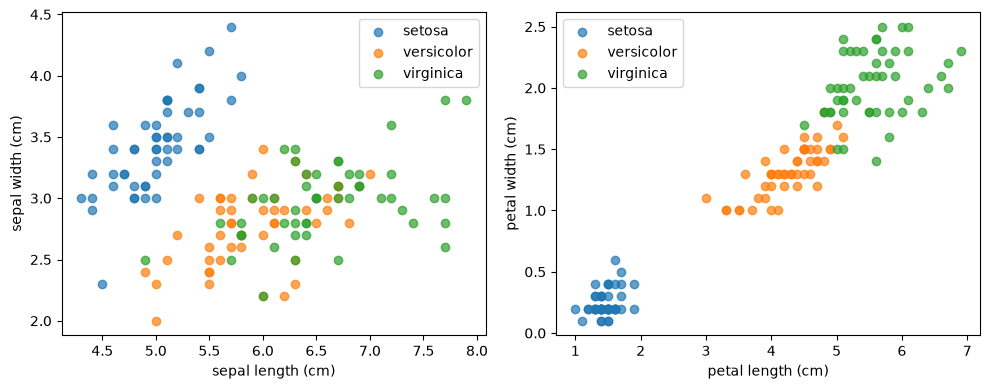

In [22]:
iris = load_iris()
X = iris.data
y = iris.target
noms_especes = iris.target_names
noms_variables = iris.feature_names
print("Forme des données :", X.shape, "| forme des étiquettes :", y.shape)
for classe, nom in enumerate(noms_especes):
    print(f"{classe} : {nom}, {np.sum(y == classe)} fleurs")
print("Première fleur :", X[0], "→", noms_especes[y[0]])

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (a, b) in zip(axes, [(0, 1), (2, 3)]):
    for classe, nom in enumerate(noms_especes):
        ax.scatter(X[y == classe, a], X[y == classe, b], label=nom, alpha=0.7)
    ax.set_xlabel(noms_variables[a])
    ax.set_ylabel(noms_variables[b])
    ax.legend()
fig.tight_layout()
plt.show()

### Lire les nuages

Sur les mesures des pétales, setosa forme un groupe bien distinct ; versicolor et virginica se recouvrent davantage. Chaque graphique ne montre que deux variables : le modèle utilisera les quatre.

On réserve ensuite des fleurs pour la **validation**, afin de comparer les réglages, et d'autres pour le **test final**. Les trois découpages sont stratifiés : ils conservent les proportions des espèces. Le normaliseur apprend sa moyenne et son écart-type **uniquement sur l'entraînement**, puis applique les mêmes valeurs ailleurs : cela évite une fuite d'information.

In [23]:
X_train_brut, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=GRAINE, stratify=y
)
X_val_brut, X_test_brut, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=GRAINE, stratify=y_temp
)
normaliseur = StandardScaler()
X_train = normaliseur.fit_transform(X_train_brut)
X_val = normaliseur.transform(X_val_brut)
X_test = normaliseur.transform(X_test_brut)
print(f"Entraînement : {len(y_train)} | validation : {len(y_val)} | test : {len(y_test)}")
print("Moyennes des 4 variables sur l'entraînement standardisé :", np.round(X_train.mean(axis=0), 3))

Entraînement : 90 | validation : 30 | test : 30
Moyennes des 4 variables sur l'entraînement standardisé : [ 0. -0.  0. -0.]


## 2. D'un neurone à un réseau

Un neurone calcule $z = w \cdot x + b$. Une couche applique ce calcul à plusieurs neurones en parallèle. Pour notre MLP :

```text
4 mesures → Linear(4, 8) → ReLU → Linear(8, 3) → softmax → 3 probabilités
             8 neurones cachés                 3 scores         3 espèces
```

La première couche apprend $8 \times 4$ poids et 8 biais ; la seconde, $3 \times 8$ poids et 3 biais : **67 paramètres** au total. Pour un vecteur colonne $x$ :

$$z_1 = W_1x+b_1,\quad a_1 = \operatorname{ReLU}(z_1),\quad z_2 = W_2a_1+b_2,\quad \hat y = \operatorname{softmax}(z_2).$$

ReLU remplace les valeurs négatives par zéro. Sans activation entre les couches, deux transformations affines se réduisent à une seule transformation affine : l'empilement n'apporte alors pas de frontière non linéaire. Softmax convertit les scores en valeurs positives dont la somme vaut 1 ; ce sont des probabilités prédites, pas nécessairement bien calibrées.

Pour visualiser le rôle des neurones, essayer [TensorFlow Playground](https://playground.tensorflow.org/) ; pour une intuition animée, voir [3Blue1Brown](https://www.3blue1brown.com/topics/neural-networks).

## 3. Une prédiction à la main, puis avec PyTorch

On suit une fleur **standardisée** de l'entraînement. Les poids sont tirés au hasard : les valeurs obtenues ne représentent pas encore un modèle appris. Les tableaux ont les dimensions $W_1 : (8,4)$ et $W_2 : (3,8)$ ; `@` effectue le produit matriciel.

In [24]:
rng = np.random.default_rng(GRAINE)
x = X_train[0]
W1 = rng.normal(0, 0.5, (8, 4))
b1 = np.zeros(8)
W2 = rng.normal(0, 0.5, (3, 8))
b2 = np.zeros(3)

z1 = W1 @ x + b1
a1 = np.maximum(0, z1)
z2 = W2 @ a1 + b2
exp_scores = np.exp(z2 - z2.max())
prob_numpy = exp_scores / exp_scores.sum()
print("Entrée :", np.round(x, 3))
print("Activations cachées :", np.round(a1, 3))
print("Probabilités :", np.round(prob_numpy, 3), "| somme :", prob_numpy.sum())
print("Espèce prédite :", noms_especes[prob_numpy.argmax()])

Entrée : [0.159 0.824 0.39  0.489]
Activations cachées : [0.677 0.    0.    0.037 0.12  0.    0.    0.014]
Probabilités : [0.256 0.341 0.403] | somme : 1.0
Espèce prédite : virginica


### Lire la propagation avant

Les zéros de la couche cachée proviennent de ReLU. La plus grande probabilité indique la classe prédite. Ici, les paramètres sont aléatoires : une bonne ou mauvaise prédiction ne démontre encore rien.

Un **tenseur** PyTorch est un tableau multidimensionnel, comparable à un tableau NumPy, qui permet aussi le calcul automatique des gradients. `nn.Module` décrit le modèle ; `forward` indique le trajet des données. Dans ce guide, le réseau renvoie des probabilités et la perte est l'erreur quadratique moyenne sur des cibles *one-hot*, comme dans le notebook d'origine.

In [25]:
class MLP(nn.Module):
    def __init__(self, neurones=8, activation=nn.ReLU):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(4, neurones),
            activation(),
            nn.Linear(neurones, 3),
        )

    def forward(self, x):
        return torch.softmax(self.net(x), dim=-1)

modele_demo = MLP()
with torch.no_grad():
    modele_demo.net[0].weight.copy_(torch.tensor(W1, dtype=torch.float32))
    modele_demo.net[0].bias.copy_(torch.tensor(b1, dtype=torch.float32))
    modele_demo.net[2].weight.copy_(torch.tensor(W2, dtype=torch.float32))
    modele_demo.net[2].bias.copy_(torch.tensor(b2, dtype=torch.float32))
    prob_torch = modele_demo(torch.tensor(x, dtype=torch.float32)).numpy()
print(modele_demo)
print("Nombre de paramètres :", sum(p.numel() for p in modele_demo.parameters()))
print("NumPy   :", np.round(prob_numpy, 6))
print("PyTorch :", np.round(prob_torch, 6))
print("Résultats proches :", np.allclose(prob_numpy, prob_torch, atol=1e-6))

MLP(
  (net): Sequential(
    (0): Linear(in_features=4, out_features=8, bias=True)
    (1): ReLU()
    (2): Linear(in_features=8, out_features=3, bias=True)
  )
)
Nombre de paramètres : 67
NumPy   : [0.256274 0.340914 0.402813]
PyTorch : [0.256274 0.340914 0.402813]
Résultats proches : True


### Lire la comparaison

Les deux calculs utilisent exactement les mêmes poids, biais et entrée ; ils doivent donc fournir les mêmes probabilités à l'arrondi près. Dans la suite, un **nouveau modèle** sera entraîné : copier ces poids n'était qu'une vérification pédagogique.

## 4. La perte et la rétropropagation

Pour une fleur de classe 1, la cible *one-hot* est $[0,1,0]$. La perte quadratique moyenne (MSE) mesure l'écart entre les trois probabilités et cette cible. Elle est utilisable pour illustrer l'apprentissage ; en classification multiclasse, l'**entropie croisée** est un choix courant : avec `nn.CrossEntropyLoss`, le modèle doit alors renvoyer les **scores bruts**, sans softmax préalable, et les cibles peuvent être des indices entiers.

Pour chaque paramètre, la rétropropagation applique la **règle de la chaîne** de la sortie vers l'entrée afin de calculer la dérivée de la perte. `loss.backward()` calcule ces gradients ; `optimizer.step()` met à jour les paramètres. Pour une descente de gradient sans momentum, la règle est $w \leftarrow w - \eta \frac{\partial L}{\partial w}$. Ici, SGD utilise aussi un **momentum**, qui accumule les gradients précédents : sa mise à jour n'est donc pas exactement cette formule simplifiée.

`optimizer.zero_grad()` remet les gradients à zéro avant chaque nouveau calcul. Pour une explication visuelle : [3Blue1Brown, rétropropagation](https://www.3blue1brown.com/lessons/backpropagation) ; pour le détail : [Nielsen, chapitre 2](http://neuralnetworksanddeeplearning.com/chap2.html).

In [26]:
X_train_t = torch.tensor(X_train, dtype=torch.float32)
X_val_t = torch.tensor(X_val, dtype=torch.float32)
X_test_t = torch.tensor(X_test, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.long)
y_val_t = torch.tensor(y_val, dtype=torch.long)
y_test_t = torch.tensor(y_test, dtype=torch.long)
y_train_onehot = nn.functional.one_hot(y_train_t, num_classes=3).float()
y_val_onehot = nn.functional.one_hot(y_val_t, num_classes=3).float()
print("Tenseurs d'entraînement :", X_train_t.shape, y_train_onehot.shape)
print("Classe", y_train[0], "→ cible one-hot", y_train_onehot[0].tolist())

Tenseurs d'entraînement : torch.Size([90, 4]) torch.Size([90, 3])
Classe 1 → cible one-hot [0.0, 1.0, 0.0]


## 5. Entraîner et suivre les courbes

Une **époque** correspond ici à un passage sur les 90 exemples d'entraînement. Pour simplifier la lecture, chaque mise à jour utilise tous les exemples à la fois : c'est une descente de gradient par lot complet, même si l'optimiseur PyTorch s'appelle `SGD`. Après chaque époque, on mesure la perte sur l'entraînement et la validation avec les mêmes paramètres, sans calcul de gradients.

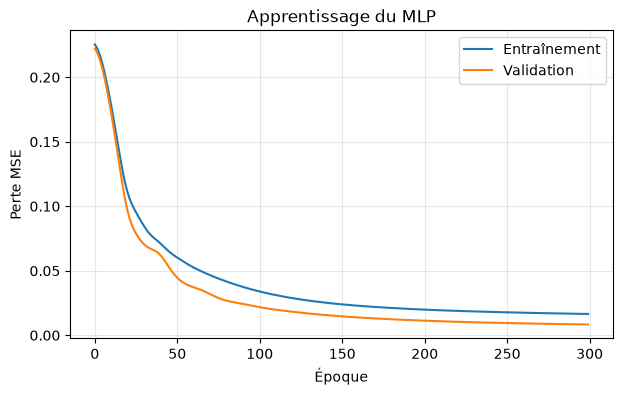

Perte initiale → finale, entraînement : 0.2254 → 0.0165
Perte initiale → finale, validation : 0.2222 → 0.0084


In [27]:
def entrainer(neurones=8, taux=0.1, epoques=300, activation=nn.ReLU):
    torch.manual_seed(GRAINE)
    modele = MLP(neurones=neurones, activation=activation)
    perte = nn.MSELoss()
    optimiseur = optim.SGD(modele.parameters(), lr=taux, momentum=0.9)
    historique = {"train": [], "validation": []}
    for _ in range(epoques):
        modele.train()
        optimiseur.zero_grad()
        cout = perte(modele(X_train_t), y_train_onehot)
        cout.backward()
        optimiseur.step()
        modele.eval()
        with torch.no_grad():
            historique["train"].append(perte(modele(X_train_t), y_train_onehot).item())
            historique["validation"].append(perte(modele(X_val_t), y_val_onehot).item())
    return modele, historique

modele, historique = entrainer()
plt.figure(figsize=(7, 4))
plt.plot(historique["train"], label="Entraînement")
plt.plot(historique["validation"], label="Validation")
plt.xlabel("Époque")
plt.ylabel("Perte MSE")
plt.title("Apprentissage du MLP")
plt.legend()
plt.grid(alpha=0.3)
plt.show()
print(f"Perte initiale → finale, entraînement : {historique['train'][0]:.4f} → {historique['train'][-1]:.4f}")
print(f"Perte initiale → finale, validation : {historique['validation'][0]:.4f} → {historique['validation'][-1]:.4f}")

### Lire les courbes

Une baisse des deux pertes indique que l'ajustement profite aussi aux fleurs de validation. Si la perte d'entraînement continue à baisser tandis que celle de validation augmente durablement, c'est un **indice** de surapprentissage, pas une preuve à partir d'une seule courbe. Ici, validation et test ne servent jamais à calculer les gradients.

## 6. Comparer les réglages sans toucher au test

On entraîne des modèles neufs avec différents nombres de neurones, puis différents taux d'apprentissage. La graine et les autres réglages restent identiques. Les comparaisons utilisent **la validation**, pas le test. À titre d'exemple, on conserve le modèle de référence de la section 5 pour l'évaluation finale, sans choisir le meilleur essai ici. Modifier une variable à la fois aide à comprendre son effet, mais changer la taille du réseau change aussi les poids initialisés : les résultats ne sont pas une preuve générale sur toutes les graines.

In [28]:
def exactitude_validation(modele):
    modele.eval()
    with torch.no_grad():
        predictions = modele(X_val_t).argmax(dim=1)
    return (predictions == y_val_t).float().mean().item()

for neurones in (1, 8, 64):
    essai, _ = entrainer(neurones=neurones)
    print(f"{neurones:2d} neurones cachés : validation = {exactitude_validation(essai):.3f}")
for taux in (0.001, 0.1, 1.0):
    essai, pertes = entrainer(taux=taux)
    print(f"taux {taux:5g} : validation = {exactitude_validation(essai):.3f}, perte = {pertes['validation'][-1]:.4f}")

 1 neurones cachés : validation = 1.000
 8 neurones cachés : validation = 1.000
64 neurones cachés : validation = 1.000
taux 0.001 : validation = 0.867, perte = 0.1906
taux   0.1 : validation = 1.000, perte = 0.0084
taux     1 : validation = 1.000, perte = 0.0019


### Lire les comparaisons

Davantage de neurones signifie davantage de paramètres, pas nécessairement une meilleure généralisation. Un taux trop petit peut rendre l'apprentissage lent ; un taux trop grand peut le rendre instable. Les effets dépendent des données, de l'initialisation et du nombre d'époques. Sans ReLU, `activation=nn.Identity` compose deux couches affines : la frontière du modèle reste linéaire, mais son score sur Iris ne doit pas nécessairement chuter.

### 6.1 Une sortie et une perte adaptées à chaque tâche

Le nombre de sorties et la perte dépendent de la **question posée**, pas seulement du nombre de couches cachées. Pour un lot de $N$ exemples :

| Tâche | Sortie du modèle | Cible | Perte PyTorch | Pour lire la prédiction |
|---|---|---|---|---|
| Binaire, deux classes exclusives | Un score brut, forme `(N, 1)` | 0 ou 1 en flottant, forme `(N, 1)` | `BCEWithLogitsLoss` | `sigmoid(score)` ; seuil à 0,5 par exemple |
| Multiclasse, une classe parmi $C$ | $C$ scores bruts, forme `(N, C)` | Indices entiers `long`, forme `(N,)` | `CrossEntropyLoss` | `softmax(scores)` ou `argmax(scores)` |
| Régression d'une valeur | Une valeur réelle, forme `(N, 1)` | Valeurs réelles flottantes, forme `(N, 1)` | `MSELoss` | Valeur prédite directement |

**Attention** : ne pas appliquer `sigmoid` avant `BCEWithLogitsLoss`, ni `softmax` avant `CrossEntropyLoss` : ces pertes intègrent les opérations appropriées de façon numériquement stable. Une classification binaire peut aussi être modélisée avec deux scores et `CrossEntropyLoss`. Le multi-étiquette, où plusieurs classes peuvent être vraies simultanément, est encore un autre cas.

La cellule suivante vérifie les formes et calcule une perte d'exemple pour chaque tâche. Elle ne prétend pas entraîner trois modèles.

In [29]:
# Deux exemples fictifs ; les scores ne sont pas encore des probabilités.
scores_binaires = torch.tensor([[0.7], [-1.0]])
cibles_binaires = torch.tensor([[1.0], [0.0]])
scores_classes = torch.tensor([[1.2, 0.1, -0.5], [-0.3, 0.2, 0.9]])
cibles_classes = torch.tensor([0, 2], dtype=torch.long)
predictions_regression = torch.tensor([[2.3], [3.4]])
cibles_regression = torch.tensor([[2.0], [4.0]])

print("Binaire :", scores_binaires.shape, cibles_binaires.shape,
      "| BCE =", round(nn.BCEWithLogitsLoss()(scores_binaires, cibles_binaires).item(), 4),
      "| probabilités =", torch.sigmoid(scores_binaires).flatten().tolist())
print("Multiclasse :", scores_classes.shape, cibles_classes.shape,
      "| entropie croisée =", round(nn.CrossEntropyLoss()(scores_classes, cibles_classes).item(), 4),
      "| classes =", scores_classes.argmax(dim=1).tolist())
print("Régression :", predictions_regression.shape, cibles_regression.shape,
      "| MSE =", round(nn.MSELoss()(predictions_regression, cibles_regression).item(), 4))

Binaire : torch.Size([2, 1]) torch.Size([2, 1]) | BCE = 0.3582 | probabilités = [0.6681877374649048, 0.2689414322376251]
Multiclasse : torch.Size([2, 3]) torch.Size([2]) | entropie croisée = 0.5012 | classes = [0, 2]
Régression : torch.Size([2, 1]) torch.Size([2, 1]) | MSE = 0.225


### Lire les sorties

Pour la classification, l'indice de la sortie est une classe ; pour la régression, la sortie est une mesure numérique. Les exemples ci-dessus ont deux observations : les dimensions de la sortie et de la cible doivent être compatibles avec la perte choisie.

Dans la suite, Iris est un problème **multiclasse**. Nous construisons un second MLP qui renvoie les scores bruts et utilisons l'entropie croisée. Il ne remplace pas le modèle MSE de la section 5 : les deux approches restent visibles pour apprendre à les distinguer.

### 6.2 Entraîner avec des mini-lots : que change chaque hyperparamètre ?

| Réglage | Effet à observer |
|---|---|
| Couches cachées | La profondeur : chaque couche ajoute une transformation et une activation. |
| Neurones par couche | La largeur et le nombre de paramètres ; plus grand ne signifie pas toujours meilleur. |
| Taux d'apprentissage | La taille des mises à jour ; trop petit peut ralentir, trop grand peut déstabiliser. |
| Époques | Nombre de passages sur les données ; trop peu peut sous-ajuster, trop peut surajuster. |
| Taille du lot | Nombre d'exemples utilisés pour **une** mise à jour. Pour 90 fleurs et des lots de 16, une époque effectue 6 mises à jour, dont une sur 10 fleurs. |

Dans `entrainer_scores`, `couches=(8, 8)` signifie deux couches cachées de huit neurones. Les exemples d'entraînement sont mélangés à chaque époque ; le dernier lot peut être plus petit. La graine contrôle l'initialisation et le mélange. La validation est toujours évaluée en mode `eval` et sans gradients.

In [30]:
from copy import deepcopy

def creer_mlp_scores(couches=(8,), dropout=0.0):
    dimensions = (4, *couches, 3)
    modules = []
    for entree, sortie in zip(dimensions[:-2], dimensions[1:-1]):
        modules.extend([nn.Linear(entree, sortie), nn.ReLU()])
        if dropout > 0:
            modules.append(nn.Dropout(dropout))
    modules.append(nn.Linear(dimensions[-2], dimensions[-1]))
    return nn.Sequential(*modules)

def entrainer_scores(X_appr, y_appr, X_valid, y_valid, couches=(8,), taux=0.05,
                     epoques=80, taille_lot=16, poids_decay=0.0, dropout=0.0,
                     patience=None, graine=GRAINE):
    torch.manual_seed(graine)
    generateur = torch.Generator().manual_seed(graine)
    reseau = creer_mlp_scores(couches, dropout)
    optimiseur = optim.SGD(reseau.parameters(), lr=taux, momentum=0.9, weight_decay=poids_decay)
    perte = nn.CrossEntropyLoss()
    historique_scores = {"train": [], "validation": []}
    meilleure_perte = float("inf")
    meilleurs_poids = None
    meilleure_epoque = 0
    sans_progres = 0
    for epoque in range(epoques):
        reseau.train()
        ordre = torch.randperm(len(X_appr), generator=generateur)
        for debut in range(0, len(ordre), taille_lot):
            lot = ordre[debut:debut + taille_lot]
            optimiseur.zero_grad()
            cout = perte(reseau(X_appr[lot]), y_appr[lot])
            if not torch.isfinite(cout):
                raise FloatingPointError("Perte non finie : vérifier les données et le taux d'apprentissage.")
            cout.backward()
            optimiseur.step()
        reseau.eval()
        with torch.no_grad():
            perte_train = perte(reseau(X_appr), y_appr).item()
            perte_val = perte(reseau(X_valid), y_valid).item()
        if not np.isfinite(perte_train) or not np.isfinite(perte_val):
            raise FloatingPointError("Perte d'évaluation non finie.")
        historique_scores["train"].append(perte_train)
        historique_scores["validation"].append(perte_val)
        if perte_val < meilleure_perte:
            meilleure_perte = perte_val
            meilleurs_poids = deepcopy(reseau.state_dict())
            meilleure_epoque = epoque + 1
            sans_progres = 0
        else:
            sans_progres += 1
        if patience is not None and sans_progres >= patience:
            break
    if patience is not None:
        reseau.load_state_dict(meilleurs_poids)
    reseau.eval()
    return reseau, historique_scores, meilleure_epoque

modele_scores, courbes_scores, _ = entrainer_scores(X_train_t, y_train_t, X_val_t, y_val_t)
with torch.no_grad():
    scores_val = modele_scores(X_val_t)
    probabilites_val = torch.softmax(scores_val, dim=1)
    exactitude_val = (scores_val.argmax(dim=1) == y_val_t).float().mean().item()
print("Scores :", tuple(scores_val.shape), "| cibles :", tuple(y_val_t.shape))
print("Somme des probabilités (premières fleurs) :", probabilites_val[:3].sum(dim=1).tolist())
print(f"Exactitude validation : {exactitude_val:.3f}")

Scores : (30, 3) | cibles : (30,)
Somme des probabilités (premières fleurs) : [0.9999999403953552, 1.0000001192092896, 0.9999999403953552]
Exactitude validation : 1.000


### Lire les hyperparamètres

On compare ci-dessous une configuration de référence à une seule modification à la fois. Les résultats dépendent du découpage et de la graine : ce sont des observations, pas un classement universel. Une époque compte ici le même nombre de fleurs, mais pas le même nombre de mises à jour lorsque la taille des lots change.

In [31]:
reglages = [
    ("Référence", {}),
    ("Deux couches cachées", {"couches": (8, 8)}),
    ("Plus de neurones", {"couches": (32,)}),
    ("Taux plus faible", {"taux": 0.005}),
    ("Moins d'époques", {"epoques": 15}),
    ("Lot complet", {"taille_lot": len(X_train_t)}),
]
for nom, options in reglages:
    essai_scores, historique_essai, _ = entrainer_scores(
        X_train_t, y_train_t, X_val_t, y_val_t, **options
    )
    with torch.no_grad():
        score = (essai_scores(X_val_t).argmax(dim=1) == y_val_t).float().mean().item()
    print(f"{nom:23s} | paramètres : {sum(p.numel() for p in essai_scores.parameters()):4d}"
          f" | époques : {len(historique_essai['train']):3d}"
          f" | perte validation : {historique_essai['validation'][-1]:.3f} | exactitude : {score:.3f}")

Référence               | paramètres :   67 | époques :  80 | perte validation : 0.034 | exactitude : 1.000
Deux couches cachées    | paramètres :  139 | époques :  80 | perte validation : 0.046 | exactitude : 0.967
Plus de neurones        | paramètres :  259 | époques :  80 | perte validation : 0.033 | exactitude : 1.000
Taux plus faible        | paramètres :   67 | époques :  80 | perte validation : 0.140 | exactitude : 1.000
Moins d'époques         | paramètres :   67 | époques :  15 | perte validation : 0.096 | exactitude : 1.000
Lot complet             | paramètres :   67 | époques :  80 | perte validation : 0.090 | exactitude : 1.000


### 6.3 Reconnaître et limiter le surapprentissage

Si la perte d'entraînement baisse alors que celle de validation augmente durablement, le modèle s'adapte peut-être trop à l'entraînement. Une seule courbe sur 30 fleurs de validation reste bruitée : elle ne suffit pas à conclure.

- **Arrêt anticipé** : arrêter après `patience` époques sans amélioration de la perte de validation et restaurer les poids de la meilleure époque. La validation participe donc au choix du modèle ; elle ne remplace pas le test final.
- **Régularisation des poids** : `weight_decay` dans l'optimiseur pénalise les grands poids ; son effet dépend du réglage et de l'optimiseur.
- **Dropout** : pendant l'entraînement, certains neurones sont temporairement désactivés ; `eval()` le désactive pour la validation et l'inférence.

Comparons trois entraînements, sans changer le test ni prétendre que l'un gagne toujours. L'arrêt peut ne pas se déclencher avant la limite si la validation continue de s'améliorer. La courbe représente **toutes les époques exécutées**, même si l'arrêt anticipé restaure ensuite des poids plus anciens.

Sans régularisation     | époques exécutées : 120 | meilleure époque :  83 | perte du modèle rendu : 0.0274
Arrêt anticipé          | époques exécutées :  53 | meilleure époque :  43 | perte du modèle rendu : 0.0256
Weight decay + dropout  | époques exécutées : 120 | meilleure époque :  90 | perte du modèle rendu : 0.1018


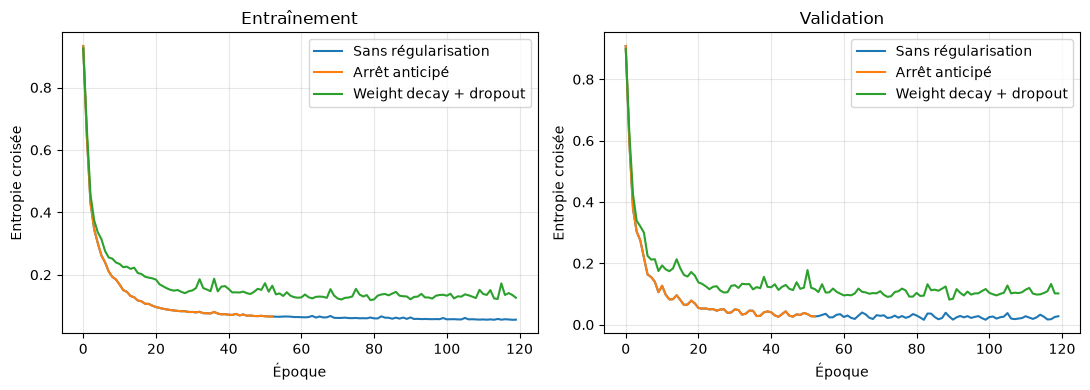

In [32]:
variantes = [
    ("Sans régularisation", {}),
    ("Arrêt anticipé", {"patience": 10}),
    ("Weight decay + dropout", {"poids_decay": 0.01, "dropout": 0.2}),
]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for nom, options in variantes:
    essai_scores, historique_essai, meilleure_epoque = entrainer_scores(
        X_train_t, y_train_t, X_val_t, y_val_t, epoques=120, **options
    )
    axes[0].plot(historique_essai["train"], label=nom)
    axes[1].plot(historique_essai["validation"], label=nom)
    with torch.no_grad():
        perte_retournee = nn.CrossEntropyLoss()(essai_scores(X_val_t), y_val_t).item()
    print(f"{nom:23s} | époques exécutées : {len(historique_essai['train']):3d}"
          f" | meilleure époque : {meilleure_epoque:3d} | perte du modèle rendu : {perte_retournee:.4f}")
for ax, titre in zip(axes, ("Entraînement", "Validation")):
    ax.set(title=titre, xlabel="Époque", ylabel="Entropie croisée")
    ax.grid(alpha=0.3)
    ax.legend()
fig.tight_layout()
plt.show()

### 6.4 Diagnostiquer un apprentissage qui ne progresse pas

Avant de modifier l'architecture, vérifier :

1. **Données et cible** : valeurs finies, classes correctes et même ordre des lignes entre entrées et étiquettes ; normaliseur ajusté sur l'entraînement seul.
2. **Dimensions et types** : pour Iris, `(N, 4)` en entrée, `(N, 3)` en scores et `(N,)` en indices entiers. Ne pas appliquer softmax avant l'entropie croisée.
3. **Boucle** : `zero_grad()` avant `backward()`, puis `step()` ; les paramètres doivent être ceux de l'optimiseur. Un gradient nul ou non fini peut signaler un problème, mais certains gradients nuls sont normaux avec ReLU.
4. **Courbes et taux** : comparer le début et la fin de la perte d'entraînement. Si elle reste élevée, essayer un taux différent ou plus d'époques ; si elle diverge, vérifier d'abord les données et réduire le taux.
5. **Généralisation** : une bonne perte d'entraînement et une validation mauvaise demandent une investigation du surapprentissage ou du découpage.

Cette cellule inspecte un mini-lot du modèle à scores et calcule un gradient à titre de diagnostic, sans mettre à jour ses poids.

In [33]:
modele_scores.train()
modele_scores.zero_grad()
X_lot, y_lot = X_train_t[:16], y_train_t[:16]
scores_lot = modele_scores(X_lot)
perte_lot = nn.CrossEntropyLoss()(scores_lot, y_lot)
perte_lot.backward()
print("Entrées :", tuple(X_lot.shape), X_lot.dtype,
      "| scores :", tuple(scores_lot.shape), scores_lot.dtype,
      "| cibles :", tuple(y_lot.shape), y_lot.dtype)
print("Valeurs finies :", bool(torch.isfinite(X_lot).all() and torch.isfinite(scores_lot).all()))
for nom, parametre in modele_scores.named_parameters():
    norme = parametre.grad.norm().item()
    print(f"Gradient {nom:12s} : norme = {norme:.6f}")
modele_scores.zero_grad()
modele_scores.eval()
print(f"Perte train, début → fin : {courbes_scores['train'][0]:.3f} → {courbes_scores['train'][-1]:.3f}")

Entrées : (16, 4) torch.float32 | scores : (16, 3) torch.float32 | cibles : (16,) torch.int64
Valeurs finies : True
Gradient 0.weight     : norme = 0.186196
Gradient 0.bias       : norme = 0.144715
Gradient 2.weight     : norme = 0.122619
Gradient 2.bias       : norme = 0.056819
Perte train, début → fin : 0.933 → 0.063


### Vérifier la sensibilité au découpage

Une graine d'initialisation différente change les poids ; une graine de **découpage** différente change les fleurs vues à l'entraînement et en validation. Pour illustrer ce second effet sans consulter le test réservé, on redécoupe trois fois les 90 fleurs d'entraînement initiales en sous-entraînement et sous-validation. À chaque fois, le normaliseur est ajusté uniquement sur le sous-entraînement ; les poids utilisent la même graine.

Ces sous-validations se recouvrent : leurs scores ne sont pas des mesures indépendantes ni un intervalle de confiance. Pour une estimation plus solide, utiliser une validation croisée, puis garder le test final à part.

In [34]:
scores_decoupages = []
for graine_decoupage in (2, 11, 23):
    X_sous_train, X_sous_val, y_sous_train, y_sous_val = train_test_split(
        X_train_brut, y_train, test_size=0.2, random_state=graine_decoupage, stratify=y_train
    )
    scaler_sous_train = StandardScaler()
    X_sous_train_t = torch.tensor(scaler_sous_train.fit_transform(X_sous_train), dtype=torch.float32)
    X_sous_val_t = torch.tensor(scaler_sous_train.transform(X_sous_val), dtype=torch.float32)
    y_sous_train_t = torch.tensor(y_sous_train, dtype=torch.long)
    y_sous_val_t = torch.tensor(y_sous_val, dtype=torch.long)
    reseau_split, _, _ = entrainer_scores(
        X_sous_train_t, y_sous_train_t, X_sous_val_t, y_sous_val_t, graine=GRAINE
    )
    with torch.no_grad():
        score = (reseau_split(X_sous_val_t).argmax(dim=1) == y_sous_val_t).float().mean().item()
    scores_decoupages.append(score)
    print(f"Découpage {graine_decoupage:2d} : exactitude sous-validation = {score:.3f}")
print(f"Moyenne descriptive : {np.mean(scores_decoupages):.3f}")

Découpage  2 : exactitude sous-validation = 0.889
Découpage 11 : exactitude sous-validation = 0.944
Découpage 23 : exactitude sous-validation = 0.889
Moyenne descriptive : 0.907


## 7. Évaluer sur des fleurs inédites

Cette section évalue le modèle de référence `modele` entraîné avec la MSE en section 5, et non les modèles expérimentaux à scores de la section 6.

Une prédiction est correcte si l'indice de la probabilité maximale correspond à l'espèce attendue. L'**exactitude** est le nombre de fleurs correctement classées divisé par le nombre de fleurs, et non le nombre de cases one-hot correctement prédites. La matrice de confusion compte les espèces réelles en lignes et les espèces prédites en colonnes.

Exactitude sur 30 fleurs de test : 1.000


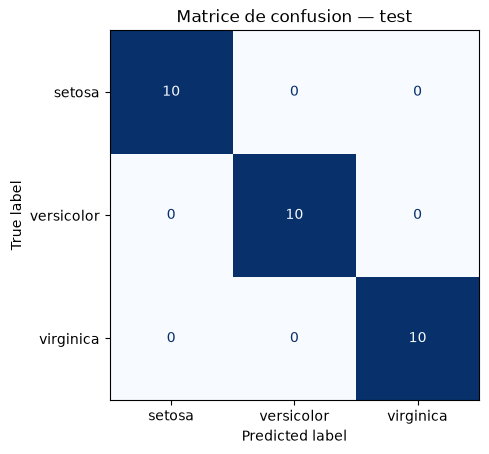

In [35]:
modele.eval()
with torch.no_grad():
    probabilites_test = modele(X_test_t).numpy()
predictions_test = probabilites_test.argmax(axis=1)
exactitude = accuracy_score(y_test, predictions_test)
print(f"Exactitude sur {len(y_test)} fleurs de test : {exactitude:.3f}")
matrice = confusion_matrix(y_test, predictions_test, labels=np.arange(3))
ConfusionMatrixDisplay(matrice, display_labels=noms_especes).plot(cmap="Blues", colorbar=False)
plt.title("Matrice de confusion — test")
plt.show()

### Lire l'évaluation

La diagonale indique les bonnes prédictions ; les autres cases indiquent les confusions entre espèces. Le test doit rester réservé à l'évaluation finale : après avoir utilisé sa performance pour modifier le modèle, il ne serait plus vraiment indépendant. Trente fleurs restent un échantillon très petit ; changer le découpage peut changer le score. Un résultat élevé ne prouve pas à lui seul que le modèle est meilleur qu'un perceptron.

## 8. Bilan — ce qu'un ingénieur IA retient du MLP

| Question | Réponse |
|---|---|
| Qu'est-ce qu'un MLP ? | Des couches entièrement connectées séparées par des activations non linéaires. |
| Que fait l'apprentissage ? | La rétropropagation calcule des gradients ; l'optimiseur ajuste poids et biais. |
| Pourquoi standardiser ? | Pour mettre les variables sur des échelles comparables, sans utiliser le test pour ajuster le normaliseur. |
| Comment évaluer ? | Comparer les réglages sur la validation ; réserver le test pour une évaluation finale et regarder aussi les confusions. |
| Quelle perte choisir ? | Selon la tâche : BCE avec scores pour le binaire, entropie croisée avec scores pour le multiclasse, MSE pour une régression simple. |
| Que surveiller ? | Dimensions, gradients, pertes train/validation et sensibilité au découpage ; l'arrêt anticipé et la régularisation peuvent aider. |

### Pour aller plus loin

1. Refaire la section 6 avec `activation=nn.Identity`, puis `nn.Tanh` : les performances changent-elles sur validation ?
2. Comparer les courbes du modèle MSE de la section 5 et du modèle à entropie croisée de la section 6 : attention, les valeurs des deux pertes ne sont pas directement comparables.
3. Revenir au XOR de DL1 et construire un réseau à couche cachée qui distingue ses quatre entrées.
4. Répéter le découpage avec plusieurs graines ou utiliser une validation croisée pour apprécier la variabilité.

### Sources

- [Iris — documentation scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_iris.html) et [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/53/iris) — données et caractéristiques.
- [scikit-learn — éviter les fuites de données](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage) — découpage et prétraitement.
- [PyTorch — construire un réseau](https://docs.pytorch.org/tutorials/beginner/basics/buildmodel_tutorial.html), [autograd](https://docs.pytorch.org/tutorials/beginner/basics/autogradqs_tutorial.html), [SGD](https://docs.pytorch.org/docs/stable/generated/torch.optim.SGD.html) et [CrossEntropyLoss](https://docs.pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html) — fonctionnement et API.
- [PyTorch — BCEWithLogitsLoss](https://docs.pytorch.org/docs/stable/generated/torch.nn.BCEWithLogitsLoss.html), [MSELoss](https://docs.pytorch.org/docs/stable/generated/torch.nn.MSELoss.html) et [Dropout](https://docs.pytorch.org/docs/stable/generated/torch.nn.Dropout.html) — pertes et régularisation.
- I. Goodfellow, Y. Bengio et A. Courville, [*Deep Learning*, chapitre 6](https://www.deeplearningbook.org/contents/mlp.html) — MLP et XOR.
- [*Dive into Deep Learning* — perceptrons multicouches](https://d2l.ai/chapter_multilayer-perceptrons/index.html) — théorie et code.
- [Michael Nielsen — *Neural Networks and Deep Learning*](http://neuralnetworksanddeeplearning.com/) — propagation et rétropropagation.
- [3Blue1Brown — réseaux de neurones](https://www.3blue1brown.com/topics/neural-networks) et [TensorFlow Playground](https://playground.tensorflow.org/) — intuition visuelle.
- [FIDLE — CNRS, UGA et MIAI](https://www.sari.cnrs.fr/Formation-Fidle-Saison-2025-2026-fr.html) — formation gratuite en français.

### Limites

Iris est un petit jeu de données pédagogique ; une seule séparation ne suffit pas pour conclure à la qualité d'un modèle en production. Les résultats peuvent varier selon les versions de bibliothèques et les environnements.